In [27]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler,StandardScaler,RobustScaler,OneHotEncoder, KBinsDiscretizer, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso, Ridge
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_squared_error
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
import category_encoders as ce
import warnings
warnings.filterwarnings('ignore')

In [28]:
# import dataset for binning example
tips = sns.load_dataset('tips')
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [29]:
# implement qcut
tips['total bill eqfreq'] = pd.qcut(tips['total_bill'],5)
tips['total_bill_eqfreq_encode'] = pd.qcut(tips['total_bill'],5,labels=range(1,6))
tips

,total_bill,tip,sex,smoker,day,time,size,total bill eqfreq,total_bill_eqfreq_encode
0,16.99,1.01,Female,No,Sun,Dinner,2,"(16.222, 19.818]",3
1,10.34,1.66,Male,No,Sun,Dinner,3,"(3.069, 12.636]",1
2,21.01,3.50,Male,No,Sun,Dinner,3,"(19.818, 26.098]",4
3,23.68,3.31,Male,No,Sun,Dinner,2,"(19.818, 26.098]",4
4,24.59,3.61,Female,No,Sun,Dinner,4,"(19.818, 26.098]",4
...,...,...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3,"(26.098, 50.81]",5
240,27.18,2.00,Female,Yes,Sat,Dinner,2,"(26.098, 50.81]",5
241,22.67,2.00,Male,Yes,Sat,Dinner,2,"(19.818, 26.098]",4
242,17.82,1.75,Male,No,Sat,Dinner,2,"(16.222, 19.818]",3


In [30]:
# equal frequency: implement qcut and encoding
tips['total_bill_eqfreq'] = pd.qcut(tips['total_bill'], 5)
tips['total_bill_eqfreq_encode'] = pd.qcut(tips['total_bill'], 5, labels=range(1,6))
tips

,total_bill,tip,sex,smoker,day,time,size,total bill eqfreq,total_bill_eqfreq_encode,total_bill_eqfreq
0,16.99,1.01,Female,No,Sun,Dinner,2,"(16.222, 19.818]",3,"(16.222, 19.818]"
1,10.34,1.66,Male,No,Sun,Dinner,3,"(3.069, 12.636]",1,"(3.069, 12.636]"
2,21.01,3.50,Male,No,Sun,Dinner,3,"(19.818, 26.098]",4,"(19.818, 26.098]"
3,23.68,3.31,Male,No,Sun,Dinner,2,"(19.818, 26.098]",4,"(19.818, 26.098]"
4,24.59,3.61,Female,No,Sun,Dinner,4,"(19.818, 26.098]",4,"(19.818, 26.098]"
...,...,...,...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3,"(26.098, 50.81]",5,"(26.098, 50.81]"
240,27.18,2.00,Female,Yes,Sat,Dinner,2,"(26.098, 50.81]",5,"(26.098, 50.81]"
241,22.67,2.00,Male,Yes,Sat,Dinner,2,"(19.818, 26.098]",4,"(19.818, 26.098]"
242,17.82,1.75,Male,No,Sat,Dinner,2,"(16.222, 19.818]",3,"(16.222, 19.818]"


In [31]:
# equal interval
tips['total_bill_eqintv'] = pd.cut(tips['total_bill'],5)
tips['total_bill_eqinterval_encode'] = pd.cut(tips['total_bill'],5,labels=range(1,6))
tips

,total_bill,tip,sex,smoker,day,time,size,total bill eqfreq,total_bill_eqfreq_encode,total_bill_eqfreq,total_bill_eqintv,total_bill_eqinterval_encode
0,16.99,1.01,Female,No,Sun,Dinner,2,"(16.222, 19.818]",3,"(16.222, 19.818]","(12.618, 22.166]",2
1,10.34,1.66,Male,No,Sun,Dinner,3,"(3.069, 12.636]",1,"(3.069, 12.636]","(3.022, 12.618]",1
2,21.01,3.50,Male,No,Sun,Dinner,3,"(19.818, 26.098]",4,"(19.818, 26.098]","(12.618, 22.166]",2
3,23.68,3.31,Male,No,Sun,Dinner,2,"(19.818, 26.098]",4,"(19.818, 26.098]","(22.166, 31.714]",3
4,24.59,3.61,Female,No,Sun,Dinner,4,"(19.818, 26.098]",4,"(19.818, 26.098]","(22.166, 31.714]",3
...,...,...,...,...,...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3,"(26.098, 50.81]",5,"(26.098, 50.81]","(22.166, 31.714]",3
240,27.18,2.00,Female,Yes,Sat,Dinner,2,"(26.098, 50.81]",5,"(26.098, 50.81]","(22.166, 31.714]",3
241,22.67,2.00,Male,Yes,Sat,Dinner,2,"(19.818, 26.098]",4,"(19.818, 26.098]","(22.166, 31.714]",3
242,17.82,1.75,Male,No,Sat,Dinner,2,"(16.222, 19.818]",3,"(16.222, 19.818]","(12.618, 22.166]",2


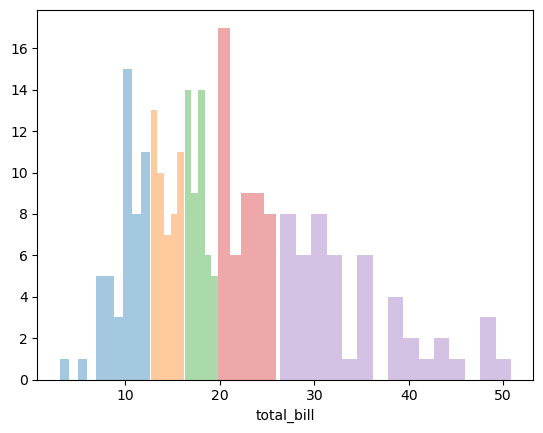

In [32]:
# plot the distribution with new binning (equal frequency)
for i, j in zip(range(1,6),[10, 5, 5, 5, 15]):
    sns.distplot(tips[tips['total_bill_eqfreq_encode'] == i]['total_bill'], kde = False, bins = j)

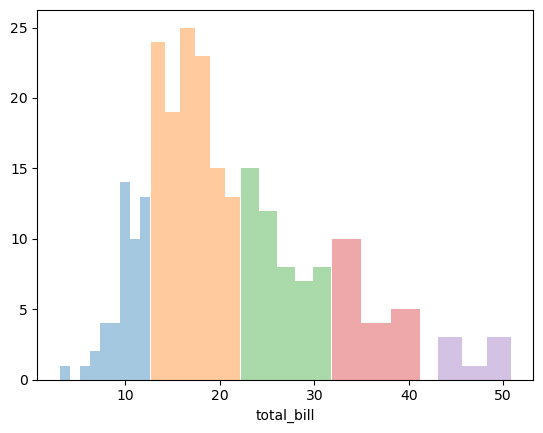

In [33]:
# plot the distribution with new binning (equal interval)
for i in range(1,6):
    sns.distplot(tips[tips['total_bill_eqinterval_encode'] == i]['total_bill'], kde = False)

In [34]:
disk = pd.read_csv('Dataset/disk.csv')

In [35]:
disk['class'].value_counts()/disk.shape[0]*100

class
1    51.863963
0    48.136037
Name: count, dtype: float64

In [36]:
# applying equal interval to the x
disk['x_eqintv'] = pd.cut(disk['x'],7)
disk['x_eqint_encode'] = pd.cut(disk['x'],7,labels=range(1,8))
disk

,x,class,x_eqintv,x_eqint_encode
0,51,0,"(46.0, 53.0]",5
1,19,1,"(17.951, 25.0]",1
2,66,1,"(60.0, 67.0]",7
3,35,0,"(32.0, 39.0]",3
4,64,1,"(60.0, 67.0]",7
...,...,...,...,...
1524,58,1,"(53.0, 60.0]",6
1525,64,1,"(60.0, 67.0]",7
1526,47,0,"(46.0, 53.0]",5
1527,26,1,"(25.0, 32.0]",2


In [37]:
# see proportion for bin vs each class
pd.crosstab(disk['x_eqintv'],disk['class'],normalize=0)

class,0,1
x_eqintv,,
"(17.951, 25.0]",0.224670,0.775330
"(25.0, 32.0]",0.537037,0.462963
"(32.0, 39.0]",0.835616,0.164384
"(39.0, 46.0]",0.846561,0.153439
"(46.0, 53.0]",0.583673,0.416327
"(53.0, 60.0]",0.302632,0.697368
"(60.0, 67.0]",0.068293,0.931707


<Axes: xlabel='x_eqintv'>

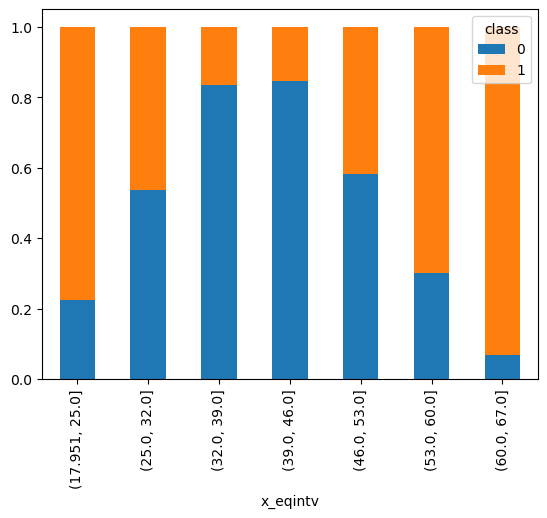

In [38]:
# plot
pd.crosstab(disk['x_eqintv'],disk['class'],normalize=0).plot(kind = 'bar', stacked = True, fontsize=10)

In [39]:
# create model WITHOUT binngin
# define dataset
X = disk[['x']]
y = disk[['class']]

# split
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=2020
)

In [40]:
# define the model
logreg = LogisticRegression()
logreg.fit(X_train,y_train)

LogisticRegression()

In [41]:
# predict
y_pred = logreg.predict(X_test)
print('accuracy',accuracy_score(y_pred,y_test))

accuracy 0.49673202614379086


In [42]:
# create model WITH binning
discretize = KBinsDiscretizer(n_bins = 7,encode = 'onehot', strategy = 'uniform')
discretize.fit(X_train)
X_train_disc = discretize.transform(X_train)
X_test_disc = discretize.transform(X_test)

In [43]:
# discretize interval
discretize.bin_edges_

array([array([18., 25., 32., 39., 46., 53., 60., 67.])], dtype=object)

In [44]:
logreg = LogisticRegression()
logreg.fit(X_train_disc,y_train)

LogisticRegression()

In [45]:
y_pred = logreg.predict(X_test_disc)
print('accuracy', accuracy_score(y_test,y_pred))

accuracy 0.7875816993464052


In [46]:
df_adult = pd.read_csv('Dataset/adult.csv')
df_adult

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


In [50]:
df_adult.isna().sum()/df_adult.shape[0]*100

age               0.0
workclass         0.0
fnlwgt            0.0
education         0.0
education.num     0.0
marital.status    0.0
occupation        0.0
relationship      0.0
race              0.0
sex               0.0
capital.gain      0.0
capital.loss      0.0
hours.per.week    0.0
native.country    0.0
income            0.0
dtype: float64

In [69]:
# define the preprocess scheme
binary_encoder_pipeline = Pipeline(
    [('imputer',SimpleImputer(strategy='constant',fill_value='NC')),
     ('binary encoder',ce.BinaryEncoder())
    ]
)

transformer = ColumnTransformer([
    ('one hot encoder',OneHotEncoder(drop='first'),['relationship','race','sex']),
    ('binary encoder',binary_encoder_pipeline,['workclass','marital.status','occupation','native.country'])
], remainder='passthrough')

In [70]:
# splitting
X = df_adult.drop(columns=['fnlwgt','income','education'])
y = np.where(df_adult['income']=='>50K',1,0)

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=2020
)

In [71]:
# preprocessing
X_train_preprocessed = pd.DataFrame(transformer.fit_transform(X_train))
X_test_preprocessed = pd.DataFrame(transformer.fit_transform(X_test))
X_train_preprocessed

,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,45.0,10.0,15024.0,0.0,99.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,31.0,10.0,0.0,0.0,37.0
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,18.0,6.0,0.0,0.0,30.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,1.0,0.0,53.0,16.0,15024.0,0.0,60.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,43.0,9.0,0.0,0.0,40.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26043,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,29.0,13.0,0.0,0.0,50.0
26044,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,60.0,6.0,0.0,0.0,40.0
26045,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,20.0,10.0,0.0,0.0,40.0
26046,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,47.0,14.0,0.0,0.0,50.0


In [72]:
# one hot encoder
transformer.transformers_[0][1].get_feature_names_out()

array(['relationship_Not-in-family', 'relationship_Other-relative',
       'relationship_Own-child', 'relationship_Unmarried',
       'relationship_Wife', 'race_Asian-Pac-Islander', 'race_Black',
       'race_Other', 'race_White', 'sex_Male'], dtype=object)

In [73]:
# bianry encoder
transformer.transformers_[1][1]['binary encoder'].get_feature_names_out()

array(['0_0', '0_1', '0_2', '0_3', '1_0', '1_1', '1_2', '2_0', '2_1',
       '2_2', '2_3', '3_0', '3_1', '3_2', '3_3', '3_4', '3_5'],
      dtype=object)

In [74]:
# construct a list
list_one_hot = list(transformer.transformers_[0][1].get_feature_names_out())
list_binary = list(transformer.transformers_[1][1]['binary encoder'].get_feature_names_out())

In [75]:
# final features
features = list_one_hot + list_binary + ['age', 'education.num', 'capital.gain','capital.loss','hours.per.week']
X_train_preprocessed.columns= features
X_test_preprocessed.columns= features
X_train_preprocessed


,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Male,...,3_1,3_2,3_3,3_4,3_5,age,education.num,capital.gain,capital.loss,hours.per.week
0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,45.0,10.0,15024.0,0.0,99.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,31.0,10.0,0.0,0.0,37.0
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,18.0,6.0,0.0,0.0,30.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,1.0,0.0,53.0,16.0,15024.0,0.0,60.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,43.0,9.0,0.0,0.0,40.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26043,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,29.0,13.0,0.0,0.0,50.0
26044,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,60.0,6.0,0.0,0.0,40.0
26045,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,20.0,10.0,0.0,0.0,40.0
26046,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,47.0,14.0,0.0,0.0,50.0


In [76]:
# model fitting and evaluating: D3
model = DecisionTreeClassifier(max_depth=5)
model.fit(X_train_preprocessed,y_train)

y_pred = model.predict(X_test_preprocessed)
print('accuracy', accuracy_score(y_pred,y_test))

accuracy 0.7853523721787194


In [77]:
# model properties
importance_table = pd.DataFrame(
    {'imp':model.feature_importances_},index=features
)
# importance_table



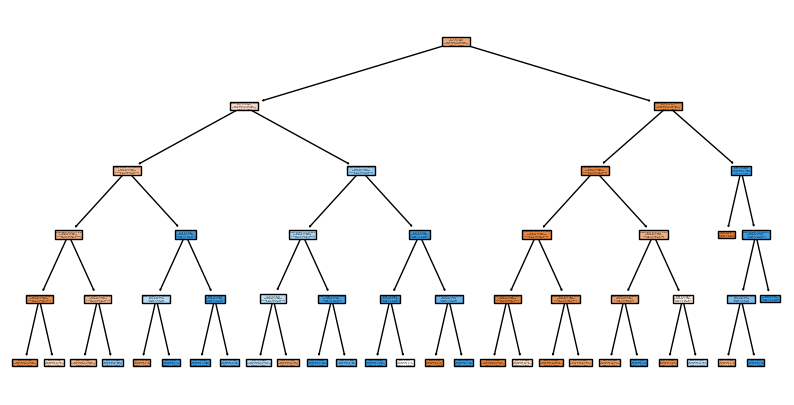

In [78]:
#last plot
plt.figure(figsize=(10,5))
plot_tree(model, feature_names=features,filled=True,class_names=['<50k','>50k'])
plt.show()